<a href="https://colab.research.google.com/github/rafiptrnto/UTSDEEPLEARNING/blob/task3-klaster/kode/task3_cluster/task3_klaster.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Task 3 — Tahap 2: Pengelompokan Klasik, Jumlah Klaster, dan Kemandirian terhadap Mikroskop

**Ruang lingkup.** Tahap ini memakai embedding dari tahap 1 (representasi tanpa label dan fusi gambar-spektrum) dan menjawab: berapa jumlah klaster yang didukung data, representasi dan metode mana yang menghasilkan klaster paling meyakinkan, dan apakah klaster mengikuti material atau hanya mengikuti mikroskop.

**Isi.**
1. **Jumlah klaster** untuk k = 2 sampai 12 pada setiap representasi dengan empat kriteria: silhouette, indeks Davies-Bouldin, BIC dari model campuran Gaussian (GMM), dan kestabilan (ARI antar dua K-Means yang dilatih pada separuh sampel berbeda). Inersia (siku) dan indeks Calinski-Harabasz ditampilkan sebagai pelengkap.
2. **Perbandingan representasi** pada jumlah klaster yang sama, termasuk pembanding PCA, dengan peringkat gabungan dari silhouette, Davies-Bouldin, kestabilan, dan ketergantungan terhadap mikroskop.
3. **Tiga metode** pada representasi terbaik: K-Means, GMM, dan *agglomerative* (Ward) beserta kesesuaian antar metode.
4. **Visualisasi** UMAP (atau t-SNE) berwarna menurut klaster dan menurut mikroskop.
5. **Serah-terima ke tahap 3** (DEC): jumlah klaster terpilih, representasi terbaik, serta pusat dan label K-Means untuk inisialisasi.

**Catatan penting tentang mikroskop.** Kolom `mikroskop` bukan label kelas, melainkan keterangan alat. Karena itu ARI dan NMI klaster terhadap mikroskop dipakai sebagai **diagnosis kebocoran efek alat**: nilai mendekati 0 berarti klaster tidak mengikuti alat (baik), nilai tinggi berarti klaster hanya memisahkan M1 dari M2 (buruk). Ini bukan skor kebenaran.

**Alur.** 0 Persiapan → 1 Embedding → 2 Kriteria jumlah klaster → 3 Pilihan k → 4 Perbandingan representasi → 5 Perbandingan metode → 6 Visualisasi → 7 Serah-terima → 8 Kesimpulan → 9 Commit.

## 0. Persiapan

Tahap ini cukup berjalan di CPU. Embedding berasal dari tahap 1 yang dikerjakan di repositori lain; sel di bawah mengambilnya dari branch `main` organisasi, dan bila belum ada akan mencoba mengambil dari branch tahap 1 di fork mitra.

In [1]:
AKUN_GITHUB = 'rafiptrnto'
EMAIL_GITHUB = 'rafiputranto665@gmail.com'
FORK_TAHAP1 = 'https://github.com/siojzz/UTSDEEPLEARNING.git'   # cadangan bila tahap 1 belum di-merge
CABANG_TAHAP1 = 'task3-representasi'

SEED = 0
K_RENTANG = list(range(2, 13))
N_SIL = 8000

import numpy, pandas, sklearn, sys, warnings, time, json, os
warnings.filterwarnings('ignore')
print("Python", sys.version.split()[0], "| numpy", numpy.__version__, "| pandas", pandas.__version__, "| sklearn", sklearn.__version__)

Python 3.13.18 | numpy 2.4.6 | pandas 2.2.3 | sklearn 1.6.1


In [2]:
if not os.path.exists('/content/data/clustering_meta.csv'):
    !gdown 10lRGd1QRfLJxwdBh1FaItJih-UgO9vpb -O /content/data_uts_dl.zip
    !mkdir -p /content/data && unzip -q /content/data_uts_dl.zip -d /content/data
!ls /content/data

Downloading...
From (original): https://drive.google.com/uc?id=10lRGd1QRfLJxwdBh1FaItJih-UgO9vpb
From (redirected): https://drive.google.com/uc?id=10lRGd1QRfLJxwdBh1FaItJih-UgO9vpb&confirm=t&uuid=2ac7def3-13b2-4fd3-9b88-7669f3280b7a
To: /content/data_uts_dl.zip
100% 396M/396M [00:07<00:00, 55.3MB/s]
clustering_meta.csv  klasifikasi_test_meta.csv	 klasifikasi_train.npz
clustering.npz	     klasifikasi_test.npz	 rul_test.csv.gz
kamus_data.md	     klasifikasi_train_meta.csv  rul_train.csv.gz


In [3]:
from google.colab import userdata
token = userdata.get('GH_TOKEN')
if not os.path.exists('/content/UTSDEEPLEARNING'):
    !git clone https://{token}@github.com/{AKUN_GITHUB}/UTSDEEPLEARNING.git /content/UTSDEEPLEARNING
%cd /content/UTSDEEPLEARNING
!git config user.name "{AKUN_GITHUB}"
!git config user.email "{EMAIL_GITHUB}"
!git remote add upstream https://github.com/UTSDEEPLEARNING/UTSDEEPLEARNING.git 2>/dev/null || true
!git checkout main
!git pull --no-edit upstream main
if not os.path.exists('kode/task3_cluster/emb/manifest.json'):
    print("Embedding belum ada di main; mencoba branch tahap 1 pada fork mitra...")
    !git pull --no-edit {FORK_TAHAP1} {CABANG_TAHAP1}
assert os.path.exists('kode/task3_cluster/emb/manifest.json'), "Embedding tahap 1 belum tersedia. Minta mitra merge PR tahap 1 terlebih dahulu."
!git checkout -B task3-klaster
!mkdir -p kode/task3_cluster/hasil kode/task3_cluster/serah_terima
!ls kode/task3_cluster kode/task3_cluster/emb

Cloning into '/content/UTSDEEPLEARNING'...
remote: Enumerating objects: 194, done.
remote: Counting objects: 100% (19/19), done.
remote: Compressing objects: 100% (19/19), done.
remote: Total 194 (delta 0), reused 0 (delta 0), pack-reused 175 (from 2)
Receiving objects: 100% (194/194), 68.50 MiB | 24.91 MiB/s, done.
Resolving deltas: 100% (48/48), done.
/content/UTSDEEPLEARNING
Already on 'main'
Your branch is up to date with 'origin/main'.
From https://github.com/UTSDEEPLEARNING/UTSDEEPLEARNING
 * branch            main       -> FETCH_HEAD
 * [new branch]      main       -> upstream/main
Already up to date.
Switched to a new branch 'task3-klaster'
kode/task3_cluster:
bobot	     clu_model.py  hasil	 task3_representasi.ipynb
clu_data.py  emb	   serah_terima

kode/task3_cluster/emb:
ae_gambar.npy	    fusi_gabungan.npy	    pca_fusi.npy      simclr_gambar.npy
ae_spektrum.npy     fusi_simclr_concat.npy  pca_gambar.npy
fusi_ae_concat.npy  manifest.json	    pca_spektrum.npy


### Kode pendukung

`clu_cluster.py` berisi pengelompokan klasik dan kriteria jumlah klaster (tanpa PyTorch).

| Fungsi | Isi |
|---|---|
| `kriteria_k` | inersia, silhouette (sub-sampel), Davies-Bouldin, Calinski-Harabasz, BIC GMM, dan kestabilan untuk tiap k |
| `k_pilihan` | k yang dipilih tiap kriteria dan k konsensus (median keempat kriteria) |
| `ukuran_pada_k` | ukuran mutu K-Means pada satu k beserta diagnosis mikroskop |
| `gmm_label` | GMM kovarians diagonal pada PCA 16 dimensi |
| `aglo_prototipe` | Ward pada 600 prototipe K-Means (Ward langsung pada 36.000 sampel memerlukan matriks jarak terlalu besar) |
| `uji_mikroskop` | ARI, NMI, dan kemurnian mikroskop dari suatu klasterisasi |

In [4]:
%%writefile /content/UTSDEEPLEARNING/kode/task3_cluster/clu_cluster.py
"""Pengelompokan klasik dan kriteria jumlah klaster untuk Task 3 (tahap 2). Tanpa PyTorch."""
import json, numpy as np, pandas as pd
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.decomposition import PCA
from sklearn.mixture import GaussianMixture
from sklearn.metrics import (silhouette_score, davies_bouldin_score, calinski_harabasz_score,
                             adjusted_rand_score, normalized_mutual_info_score)


def muat_emb(folder):
    man = json.load(open(f'{folder}/manifest.json'))
    emb = {k: np.load(f'{folder}/{k}.npy').astype(np.float32) for k in man['embedding']}
    return emb, man


def kmeans(emb, k, seed=0, n_init=3):
    return KMeans(k, n_init=n_init, random_state=seed).fit(emb)


def gmm_label(emb, k, d_pca=16, seed=0):
    """GMM kovarians diagonal pada PCA d_pca dimensi. Mengembalikan (label, BIC)."""
    z = PCA(min(d_pca, emb.shape[1]), random_state=seed).fit_transform(emb)
    g = GaussianMixture(k, covariance_type='diag', n_init=2, reg_covar=1e-4, random_state=seed).fit(z)
    return g.predict(z), float(g.bic(z))


def aglo_prototipe(emb, k, n_proto=600, seed=0):
    """Agglomerative (Ward) pada n_proto prototipe K-Means, lalu tiap sampel mengikuti prototipenya.
    Ward langsung pada 36.000 sampel memerlukan matriks jarak terlalu besar."""
    km = KMeans(min(n_proto, len(emb) // 5), n_init=1, random_state=seed).fit(emb)
    lab_p = AgglomerativeClustering(k, linkage='ward').fit_predict(km.cluster_centers_)
    return lab_p[km.labels_]


def kestabilan(emb, k, ulang=3, seed=0, frac=0.5):
    """ARI antar dua K-Means yang dilatih pada separuh sampel acak berbeda, keduanya memberi label seluruh data."""
    rng = np.random.RandomState(seed)
    r = []
    for _ in range(ulang):
        p = rng.permutation(len(emb))
        a, b = p[:int(len(emb) * frac)], p[int(len(emb) * frac):]
        ka, kb = KMeans(k, n_init=2, random_state=int(rng.randint(1e6))).fit(emb[a]), KMeans(k, n_init=2, random_state=int(rng.randint(1e6))).fit(emb[b])
        r.append(adjusted_rand_score(ka.predict(emb), kb.predict(emb)))
    return float(np.mean(r))


def kriteria_k(emb, ks, n_sil=8000, seed=0, d_pca=16):
    """Per k: inersia, silhouette (sub-sampel), Davies-Bouldin, Calinski-Harabasz, BIC GMM, kestabilan."""
    rng = np.random.RandomState(seed)
    isub = rng.choice(len(emb), min(n_sil, len(emb)), replace=False)
    out = []
    for k in ks:
        km = kmeans(emb, k, seed)
        _, bic = gmm_label(emb, k, d_pca, seed)
        out.append(dict(k=int(k), inersia=float(km.inertia_),
                        silhouette=float(silhouette_score(emb[isub], km.labels_[isub])),
                        dbi=float(davies_bouldin_score(emb, km.labels_)),
                        ch=float(calinski_harabasz_score(emb, km.labels_)),
                        bic=bic, kestabilan=kestabilan(emb, k, seed=seed)))
    return pd.DataFrame(out)


def k_pilihan(df, ambang_stab=0.8):
    """k yang dipilih tiap kriteria. Kestabilan: k terbesar dengan ARI >= ambang (bila tak ada: k dengan ARI tertinggi).
    Konsensus: median dari empat kriteria, dibulatkan."""
    p = dict(silhouette=int(df.loc[df.silhouette.idxmax(), 'k']),
             dbi=int(df.loc[df.dbi.idxmin(), 'k']),
             bic=int(df.loc[df.bic.idxmin(), 'k']))
    ok = df[df.kestabilan >= ambang_stab]
    p['kestabilan'] = int(ok.k.max()) if len(ok) else int(df.loc[df.kestabilan.idxmax(), 'k'])
    p['konsensus'] = int(round(float(np.median([p['silhouette'], p['dbi'], p['bic'], p['kestabilan']]))))
    return p


def uji_mikroskop(label, mik):
    """ARI dan NMI klaster terhadap mikroskop (dekat 0 = klaster tidak mengikuti alat) serta kemurnian mikroskop terbesar."""
    mik = np.asarray(mik).astype(str)
    lab = np.asarray(label)
    ms = np.unique(mik)
    murni = 0.0
    for c in np.unique(lab):
        i = lab == c
        murni += max((mik[i] == m).sum() for m in ms)
    return dict(ari=float(adjusted_rand_score(mik, lab)), nmi=float(normalized_mutual_info_score(mik, lab)),
                kemurnian=float(murni / len(lab)), mayoritas=float(max((mik == m).mean() for m in ms)))


def ukuran_pada_k(emb, k, mik, seed=0, n_sil=8000):
    km = kmeans(emb, k, seed)
    rng = np.random.RandomState(seed)
    isub = rng.choice(len(emb), min(n_sil, len(emb)), replace=False)
    u = uji_mikroskop(km.labels_, mik)
    return dict(silhouette=float(silhouette_score(emb[isub], km.labels_[isub])), dbi=float(davies_bouldin_score(emb, km.labels_)),
                kestabilan=kestabilan(emb, k, seed=seed), mik_nmi=u['nmi'], mik_ari=u['ari'], mik_kemurnian=u['kemurnian'],
                ukuran_min=float(np.bincount(km.labels_).min() / len(emb))), km


def peringkat_gabungan(df):
    """Rerata peringkat: silhouette tinggi, DBI rendah, kestabilan tinggi, NMI mikroskop rendah."""
    r = pd.DataFrame({'silhouette': df.silhouette.rank(ascending=False), 'dbi': df.dbi.rank(ascending=True),
                      'kestabilan': df.kestabilan.rank(ascending=False), 'mik_nmi': df.mik_nmi.rank(ascending=True)}, index=df.index)
    return r.mean(1)


def kesesuaian_modalitas(ea, eb, ks=range(2, 9), seed=0):
    """Kesepakatan pengelompokan dari dua modalitas: ARI dan NMI antara K-Means pada embedding A dan pada embedding B,
    untuk tiap k. Nilai dasar (permutasi label B) mendekati 0."""
    rng = np.random.RandomState(seed)
    out = []
    for k in ks:
        la, lb = kmeans(ea, k, seed).labels_, kmeans(eb, k, seed).labels_
        out.append(dict(k=int(k), ari=float(adjusted_rand_score(la, lb)), nmi=float(normalized_mutual_info_score(la, lb)),
                        ari_acak=float(adjusted_rand_score(la, rng.permutation(lb)))))
    return pd.DataFrame(out)


Writing /content/UTSDEEPLEARNING/kode/task3_cluster/clu_cluster.py


In [5]:
sys.path.insert(0, '/content/UTSDEEPLEARNING/kode/task3_cluster')
import numpy as np, pandas as pd, matplotlib.pyplot as plt
import importlib, clu_cluster
importlib.reload(clu_cluster)
from clu_cluster import *
from IPython.display import display, Markdown
OUT = '/content/UTSDEEPLEARNING/kode/task3_cluster'
INFO, HASIL = {}, {}

## 1. Embedding dari tahap 1

Embedding dibaca beserta `manifest.json`. Urutan baris sama dengan `clustering.npz` dan `clustering_meta.csv`, sehingga keterangan mikroskop dapat dipasangkan langsung per baris.

In [6]:
EMB, MAN = muat_emb(f'{OUT}/emb')
meta = pd.read_csv('/content/data/clustering_meta.csv')
if 'indeks' in meta.columns: meta = meta.sort_values('indeks').reset_index(drop=True)
mik = meta['mikroskop'].astype(str).values
assert all(len(e) == len(mik) for e in EMB.values()), "jumlah baris embedding tidak sama dengan meta"
print("normalisasi per mikroskop pada tahap 1:", MAN['normalisasi_per_mikroskop'])
print(pd.DataFrame({k: dict(dim=v.shape[1], std_rata=float(v.std(0).mean())) for k, v in EMB.items()}).T.round(3))
print(pd.Series(mik).value_counts().to_dict())
INFO['representasi'] = list(EMB.keys())
INFO['normalisasi_per_mikroskop'] = MAN['normalisasi_per_mikroskop']

# Representasi yang pada tahap 1 memuat efek mikroskop (akurasi seimbang menebak mikroskop > 0,60)
try:
    T1 = json.load(open(f'{OUT}/hasil/task3_representasi.json'))
    BOCOR = [r['representasi'] for r in T1['info']['tabel'] if r['mikroskop_seimbang'] > 0.6 and r['representasi'] in EMB]
except Exception as ex:
    print("ringkasan tahap 1 tidak terbaca:", ex); BOCOR = []
INFO['bocor'] = BOCOR
print("representasi dengan efek mikroskop kuat (dikeluarkan dari pemilihan k dan representasi terbaik):", BOCOR)

normalisasi per mikroskop pada tahap 1: True
                     dim  std_rata
pca_gambar          64.0     3.723
pca_spektrum        32.0     1.256
pca_fusi            96.0     0.142
ae_gambar           64.0     4.052
simclr_gambar       64.0     3.070
ae_spektrum         32.0     1.048
fusi_ae_concat      96.0     0.142
fusi_simclr_concat  96.0     0.142
fusi_gabungan       64.0     1.828
{'M1': 21636, 'M2': 14364}
representasi dengan efek mikroskop kuat (dikeluarkan dari pemilihan k dan representasi terbaik): ['simclr_gambar', 'fusi_simclr_concat']


## 2. Kriteria jumlah klaster

Untuk setiap representasi dihitung enam ukuran pada k = 2 sampai 12. Silhouette memakai sub-sampel 8.000 titik. BIC berasal dari GMM kovarians diagonal pada PCA 16 dimensi. Kestabilan adalah ARI rata-rata dari tiga pasangan K-Means yang dilatih pada separuh sampel yang berbeda lalu memberi label seluruh data, sehingga mengukur apakah pembagian yang sama ditemukan dari data yang berbeda. Sel ini yang paling lama (sekitar 15–25 menit di CPU).

In [7]:
t0 = time.time()
KRIT = {}
for nama, e in EMB.items():
    KRIT[nama] = kriteria_k(e, K_RENTANG, n_sil=N_SIL, seed=SEED)
    print(f"{nama:20s} selesai | {time.time() - t0:.0f} dtk")
os.makedirs(f'{OUT}/hasil', exist_ok=True)
pd.concat({k: v for k, v in KRIT.items()}, names=['representasi']).to_csv(f'{OUT}/hasil/kriteria_k.csv')

pca_gambar           selesai | 49 dtk
pca_spektrum         selesai | 83 dtk
pca_fusi             selesai | 126 dtk
ae_gambar            selesai | 163 dtk
simclr_gambar        selesai | 196 dtk
ae_spektrum          selesai | 229 dtk
fusi_ae_concat       selesai | 272 dtk
fusi_simclr_concat   selesai | 304 dtk
fusi_gabungan        selesai | 335 dtk


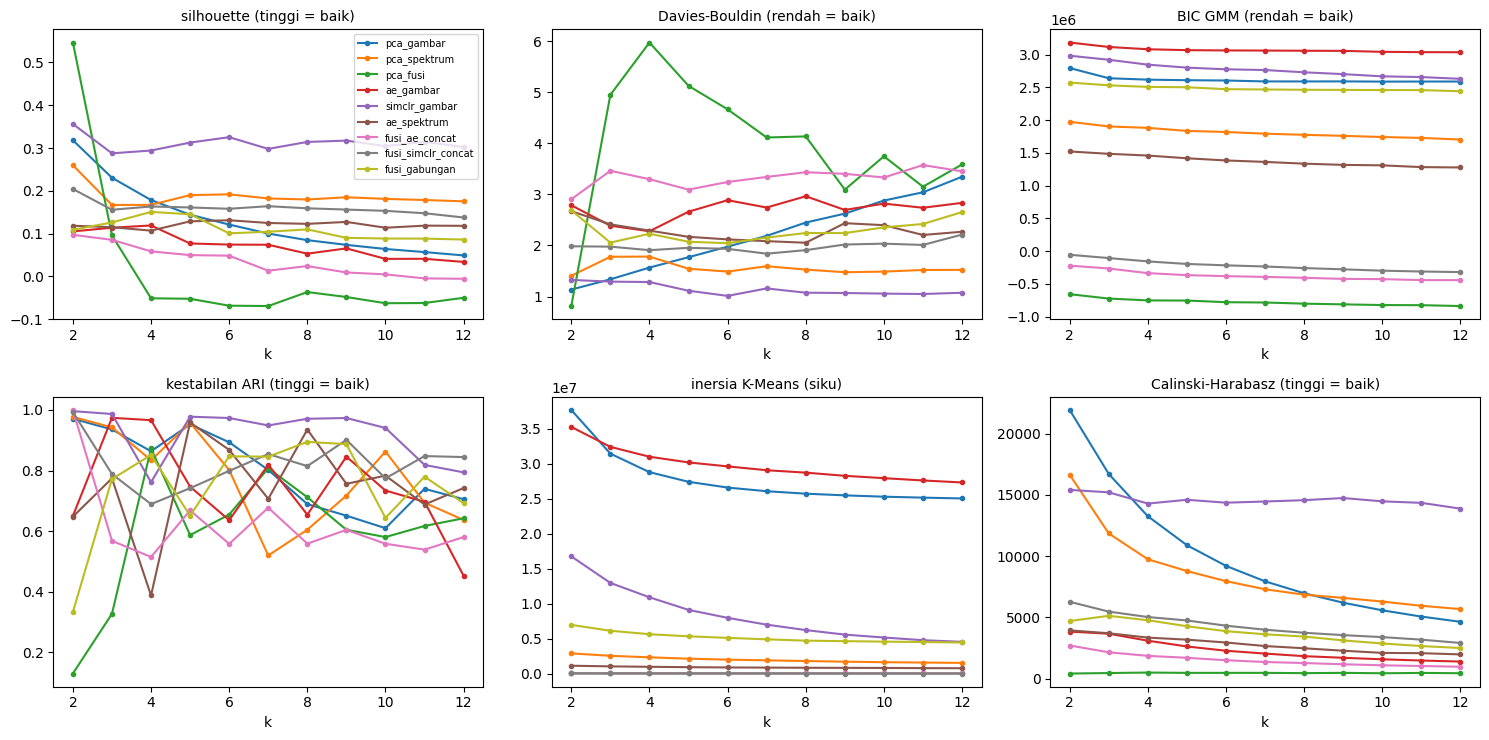

In [8]:
fig, ax = plt.subplots(2, 3, figsize=(15, 7.5))
panel = [('silhouette', 'silhouette (tinggi = baik)'), ('dbi', 'Davies-Bouldin (rendah = baik)'), ('bic', 'BIC GMM (rendah = baik)'),
         ('kestabilan', 'kestabilan ARI (tinggi = baik)'), ('inersia', 'inersia K-Means (siku)'), ('ch', 'Calinski-Harabasz (tinggi = baik)')]
for a, (kol, jd) in zip(ax.ravel(), panel):
    for nama, df in KRIT.items():
        a.plot(df.k, df[kol], marker='o', ms=3, label=nama)
    a.set_title(jd, fontsize=10); a.set_xlabel('k')
ax[0, 0].legend(fontsize=7)
plt.tight_layout(); plt.show()

## 3. Jumlah klaster yang dipilih

Setiap kriteria menunjuk satu k: silhouette tertinggi, Davies-Bouldin terendah, BIC terendah, dan untuk kestabilan k terbesar yang ARI-nya masih 0,8 atau lebih (bila tidak ada, k dengan ARI tertinggi). **Konsensus** adalah median keempat k itu. Bila k yang ditunjuk menempel pada batas rentang (2 atau 12), kriteria tersebut tidak menemukan puncak yang jelas, dan hal itu dicatat apa adanya.

In [9]:
PIL = {nama: k_pilihan(df) for nama, df in KRIT.items()}
tab_k = pd.DataFrame(PIL).T
display(tab_k)
INFO['k_pilihan'] = PIL
semua = [v['konsensus'] for n, v in PIL.items() if n not in BOCOR] or [v['konsensus'] for v in PIL.values()]
K_UMUM = int(pd.Series(semua).mode().min())
print("k konsensus per representasi:", dict(zip(PIL.keys(), semua)))
print("k bersama yang dipakai untuk membandingkan representasi (modus, tanpa representasi yang bocor mikroskop):", K_UMUM)
INFO['k_umum'] = K_UMUM

,silhouette,dbi,bic,kestabilan,konsensus
pca_gambar,2,2,10,7,4
pca_spektrum,2,2,12,10,6
pca_fusi,2,2,12,7,4
ae_gambar,4,4,12,9,6
simclr_gambar,2,6,12,11,8
ae_spektrum,6,8,12,8,8
fusi_ae_concat,2,2,12,2,2
fusi_simclr_concat,2,7,12,12,10
fusi_gabungan,4,6,12,9,8


k konsensus per representasi: {'pca_gambar': 4, 'pca_spektrum': 6, 'pca_fusi': 4, 'ae_gambar': 6, 'simclr_gambar': 8, 'ae_spektrum': 2, 'fusi_ae_concat': 8}
k bersama yang dipakai untuk membandingkan representasi (modus, tanpa representasi yang bocor mikroskop): 4


## 4. Perbandingan representasi pada k yang sama

Semua representasi dibandingkan pada k bersama di atas (K-Means, 3 inisialisasi). Empat ukuran dipakai: silhouette (tinggi lebih baik), Davies-Bouldin (rendah lebih baik), kestabilan (tinggi lebih baik), dan NMI terhadap mikroskop (rendah lebih baik, karena mikroskop adalah efek alat). Peringkat gabungan adalah rerata keempat peringkat; ini ringkasan, bukan pembuktian. Ukuran klaster terkecil dicatat untuk mendeteksi klaster remeh. Representasi yang pada tahap 1 mikroskopnya mudah ditebak (akurasi seimbang di atas 0,60) tetap ditampilkan, tetapi dikeluarkan dari pemilihan k bersama dan dari tiga representasi teratas, karena klaster di atasnya cenderung hanya memisahkan alat.

In [10]:
baris, KM = [], {}
for nama, e in EMB.items():
    u, km = ukuran_pada_k(e, K_UMUM, mik, seed=SEED, n_sil=N_SIL)
    KM[nama] = km
    baris.append(dict(representasi=nama, **u))
tab_r = pd.DataFrame(baris).set_index('representasi')
tab_r['peringkat'] = peringkat_gabungan(tab_r)
tab_r = tab_r.sort_values('peringkat')
display(tab_r.round(3))
tab_r.to_csv(f'{OUT}/hasil/perbandingan_representasi.csv')
INFO['perbandingan'] = tab_r.reset_index().to_dict('records')
tab_r['bocor_mikroskop'] = [n in BOCOR for n in tab_r.index]
display(tab_r[['peringkat', 'mik_nmi', 'bocor_mikroskop']].round(3))
LAYAK = [n for n in tab_r.index if n not in BOCOR] or list(tab_r.index)
TOP = LAYAK[:3]
print("tiga representasi teratas:", TOP)

,silhouette,dbi,kestabilan,mik_nmi,mik_ari,mik_kemurnian,ukuran_min,peringkat
representasi,,,,,,,,
pca_spektrum,0.167,1.782,0.834,0.000,-0.000,0.601,0.239,3.00
pca_gambar,0.178,1.566,0.864,0.001,-0.002,0.601,0.157,3.50
simclr_gambar,0.294,1.283,0.762,0.012,0.005,0.601,0.101,4.25
fusi_gabungan,0.151,2.229,0.851,0.000,-0.000,0.601,0.240,4.50
ae_gambar,0.119,2.277,0.966,0.000,-0.001,0.601,0.129,4.75
pca_fusi,-0.051,5.971,0.873,0.000,-0.000,0.601,0.240,5.75
fusi_simclr_concat,0.163,1.907,0.689,0.004,-0.002,0.601,0.101,5.75
ae_spektrum,0.107,2.290,0.387,0.000,0.000,0.601,0.074,6.25
fusi_ae_concat,0.058,3.296,0.515,0.000,-0.000,0.601,0.064,7.25


,peringkat,mik_nmi,bocor_mikroskop
representasi,,,
pca_spektrum,3.00,0.000,False
pca_gambar,3.50,0.001,False
simclr_gambar,4.25,0.012,True
fusi_gabungan,4.50,0.000,False
ae_gambar,4.75,0.000,False
pca_fusi,5.75,0.000,False
fusi_simclr_concat,5.75,0.004,True
ae_spektrum,6.25,0.000,False
fusi_ae_concat,7.25,0.000,False


tiga representasi teratas: ['pca_spektrum', 'pca_gambar', 'fusi_gabungan']


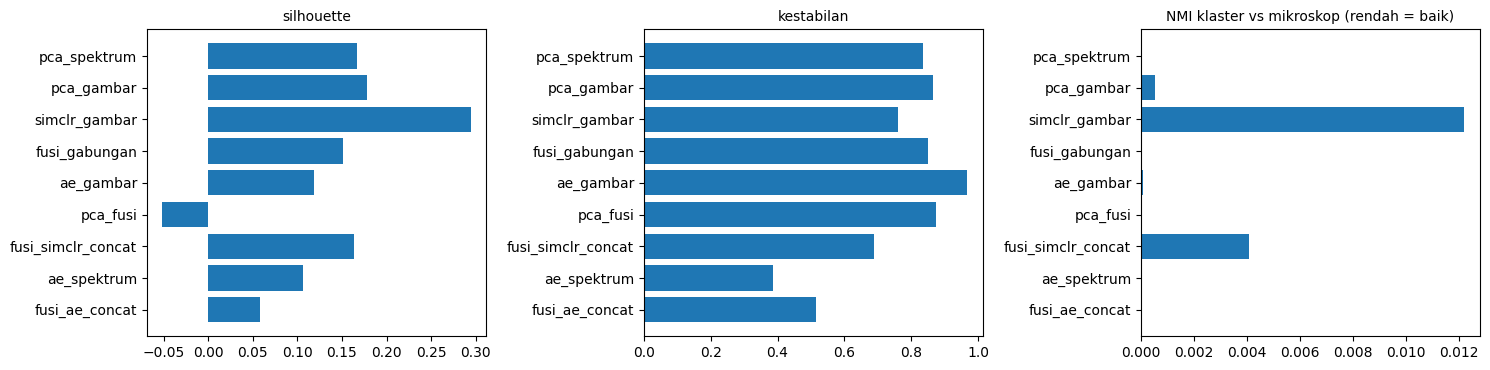

In [11]:
fig, ax = plt.subplots(1, 3, figsize=(15, 3.8))
for a, kol, jd in zip(ax, ['silhouette', 'kestabilan', 'mik_nmi'], ['silhouette', 'kestabilan', 'NMI klaster vs mikroskop (rendah = baik)']):
    a.barh(tab_r.index[::-1], tab_r[kol][::-1]); a.set_title(jd, fontsize=10)
plt.tight_layout(); plt.show()

### 4b. Kesepakatan klaster antar modalitas

Pada tahap 1, irisan tetangga terdekat antara embedding gambar dan embedding spektrum hampir sama dengan kebetulan. Ukuran itu sebenarnya tidak peka terhadap struktur klaster: bila kedua modalitas mengenali kelompok yang sama tetapi tetangga di dalam kelompok acak, irisannya hanya sekitar jumlah klaster dikali nilai kebetulan. Karena itu kesepakatan diukur langsung pada klaster: K-Means dijalankan terpisah pada embedding gambar dan pada embedding spektrum, lalu dihitung ARI dan NMI antara kedua pembagian untuk tiap k. Nilai dasar adalah ARI antara satu pembagian dan label hasil pengacakan (mendekati 0). Kesepakatan jauh di atas dasar berarti kedua modalitas memuat kelompok yang sama, dan itu alasan kuat untuk menggabungkannya.

**pca_gambar vs pca_spektrum**

k,2,3,4,5,6,7,8
ari,0.0,0.0,-0.0,-0.0,-0.0,-0.000,0.000
nmi,0.0,0.0,0.0,0.0,0.0,0.001,0.001
ari_acak,-0.0,-0.0,-0.0,0.0,0.0,0.000,0.000


**ae_gambar vs ae_spektrum**

k,2,3,4,5,6,7,8
ari,0.0,0.000,0.027,0.119,0.133,0.126,0.109
nmi,0.0,0.001,0.057,0.192,0.241,0.255,0.241
ari_acak,-0.0,-0.000,-0.000,-0.000,0.000,0.000,-0.000


**simclr_gambar vs ae_spektrum**

k,2,3,4,5,6,7,8
ari,0.0,-0.001,0.076,0.139,0.160,0.186,0.237
nmi,0.0,0.000,0.135,0.255,0.306,0.312,0.398
ari_acak,-0.0,0.001,-0.000,-0.000,-0.000,0.000,0.000


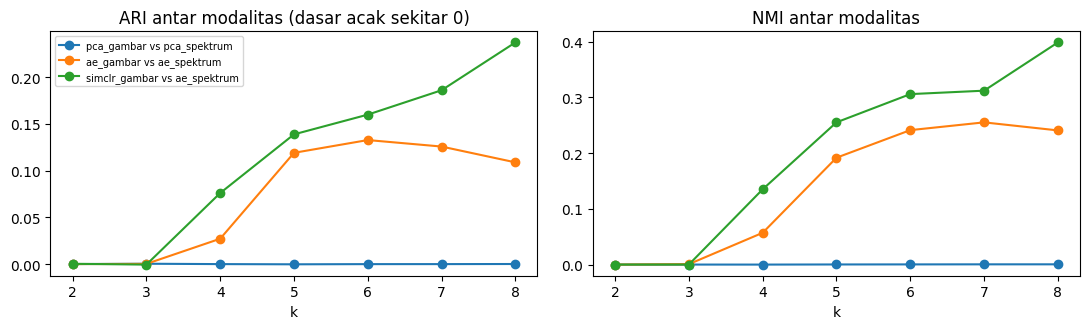

In [12]:
pasangan = [(a, b) for a, b in [('pca_gambar', 'pca_spektrum'), ('ae_gambar', 'ae_spektrum'), ('simclr_gambar', 'ae_spektrum')] if a in EMB and b in EMB]
MOD = {}
for a, b in pasangan:
    MOD[f"{a} vs {b}"] = kesesuaian_modalitas(EMB[a], EMB[b], range(2, 9), seed=SEED)
    display(Markdown(f"**{a} vs {b}**"))
    display(MOD[f"{a} vs {b}"].round(3).set_index('k').T)
fig, ax = plt.subplots(1, 2, figsize=(11, 3.4))
for nama, df in MOD.items():
    ax[0].plot(df.k, df.ari, marker='o', label=nama); ax[1].plot(df.k, df.nmi, marker='o', label=nama)
ax[0].set_title("ARI antar modalitas (dasar acak sekitar 0)"); ax[1].set_title("NMI antar modalitas"); ax[0].legend(fontsize=7)
for a_ in ax: a_.set_xlabel('k')
plt.tight_layout(); plt.show()
INFO['modalitas'] = {n: df.round(4).to_dict('records') for n, df in MOD.items()}

## 5. Perbandingan metode pada representasi terbaik

Tiga metode dijalankan pada representasi teratas dengan k bersama: K-Means, GMM (kovarians diagonal pada PCA 16 dimensi), dan *agglomerative* Ward pada 600 prototipe K-Means. Dihitung kesesuaian antar metode (ARI) dan ketergantungan tiap metode terhadap mikroskop. Kesesuaian tinggi antar metode yang berbeda prinsip menjadi bukti bahwa struktur kelompok ada pada data, bukan artefak satu algoritma.

In [13]:
terbaik = TOP[0]
e = EMB[terbaik]
LAB = {'K-Means': KM[terbaik].labels_,
       'GMM': gmm_label(e, K_UMUM, seed=SEED)[0],
       'Agglomerative (prototipe)': aglo_prototipe(e, K_UMUM, seed=SEED)}
nm = list(LAB)
M = pd.DataFrame([[adjusted_rand_score(LAB[a], LAB[b]) for b in nm] for a in nm], index=nm, columns=nm)
display(M.round(3))
tab_m = pd.DataFrame({n: dict(**uji_mikroskop(l, mik), ukuran_min=float(np.bincount(l).min() / len(l))) for n, l in LAB.items()}).T
display(tab_m.round(3))
INFO['metode'] = dict(representasi=terbaik, k=K_UMUM, kesesuaian=M.round(4).to_dict(), mikroskop=tab_m.round(4).to_dict('index'))
M.to_csv(f'{OUT}/hasil/kesesuaian_metode.csv')

,K-Means,GMM,Agglomerative (prototipe)
K-Means,1.000,0.152,0.434
GMM,0.152,1.000,0.177
Agglomerative (prototipe),0.434,0.177,1.000


,ari,nmi,kemurnian,mayoritas,ukuran_min
K-Means,-0.0,0.0,0.601,0.601,0.239
GMM,-0.0,0.0,0.601,0.601,0.177
Agglomerative (prototipe),-0.0,0.0,0.601,0.601,0.138


## 6. Visualisasi

UMAP (bila dapat dipasang; bila tidak, t-SNE) pada 12.000 sampel acak dari representasi terbaik dan pembanding PCA. Kiri: warna menurut klaster K-Means. Kanan: warna menurut mikroskop. Proyeksi dua dimensi hanya alat bantu visual dan tidak dipakai sebagai dasar keputusan.

UMAP tersedia: True


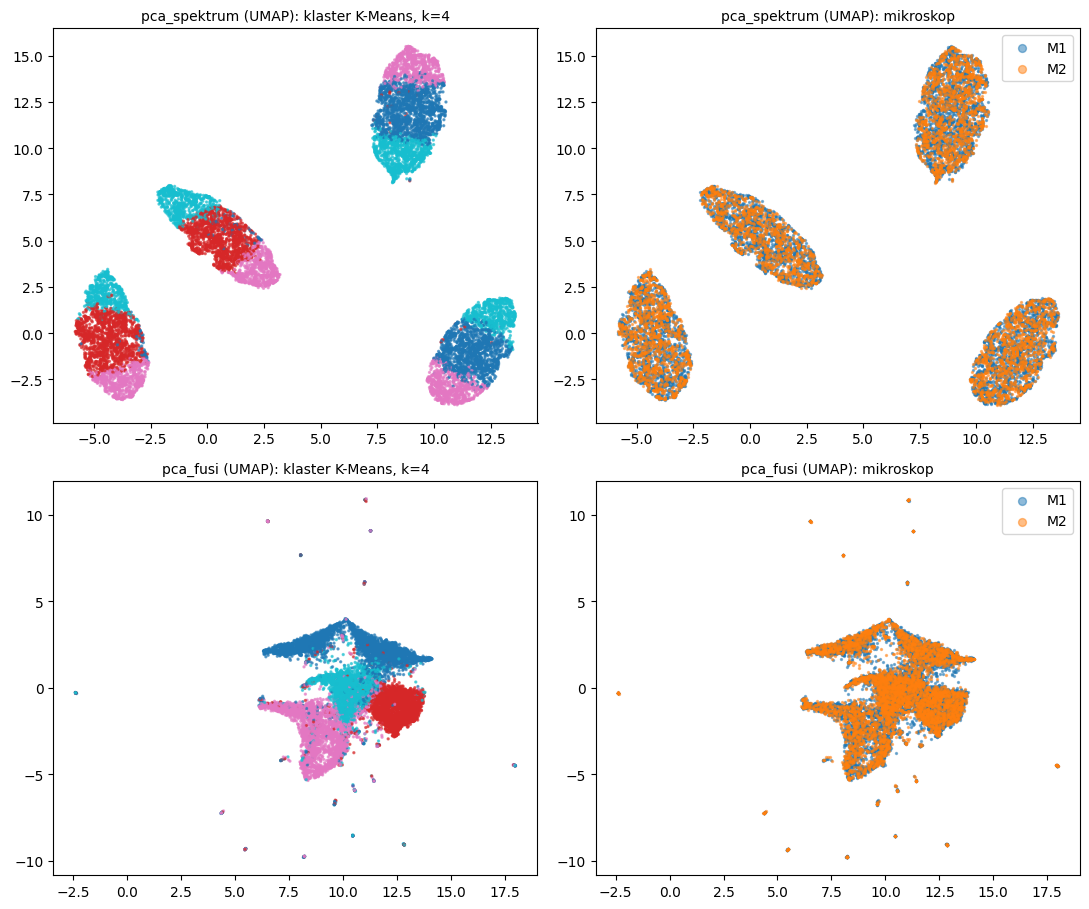

In [14]:
try:
    import umap
except ImportError:
    !pip -q install umap-learn
    try:
        import umap
    except ImportError:
        umap = None
print("UMAP tersedia:", umap is not None)
rs = np.random.RandomState(SEED).choice(len(mik), 12000, replace=False)

def proyeksi(x):
    if umap is not None:
        return umap.UMAP(n_neighbors=30, min_dist=0.1, random_state=SEED).fit_transform(x), 'UMAP'
    from sklearn.manifold import TSNE
    return TSNE(2, init='pca', random_state=SEED).fit_transform(x), 't-SNE'

tampil = [terbaik] + (['pca_fusi'] if terbaik != 'pca_fusi' and 'pca_fusi' in EMB else [])
fig, ax = plt.subplots(len(tampil), 2, figsize=(11, 4.6 * len(tampil)))
ax = np.atleast_2d(ax)
for r, n in enumerate(tampil):
    z, jenis = proyeksi(EMB[n][rs])
    lab = KM[n].labels_[rs]
    sc = ax[r, 0].scatter(z[:, 0], z[:, 1], c=lab, s=2, cmap='tab10', alpha=0.6)
    ax[r, 0].set_title(f"{n} ({jenis}): klaster K-Means, k={K_UMUM}", fontsize=10)
    for m in sorted(np.unique(mik)):
        i = mik[rs] == m
        ax[r, 1].scatter(z[i, 0], z[i, 1], s=2, alpha=0.5, label=m)
    ax[r, 1].set_title(f"{n} ({jenis}): mikroskop", fontsize=10); ax[r, 1].legend(markerscale=4)
plt.tight_layout(); plt.show()

## 7. Serah-terima ke tahap 3 (DEC)

Yang diteruskan: representasi terbaik, k konsensus, serta pusat dan label K-Means untuk representasi teratas pada k bersama. Pusat ini dipakai untuk menginisialisasi lapisan klaster DEC. Berkas disimpan di `serah_terima/` bersama `serah_terima.json` yang mencatat seluruh pilihan.

In [15]:
ST = f'{OUT}/serah_terima'
daftar = []
for n in TOP:
    np.save(f'{ST}/pusat_kmeans_{n}_k{K_UMUM}.npy', KM[n].cluster_centers_.astype(np.float32))
    np.save(f'{ST}/label_kmeans_{n}_k{K_UMUM}.npy', KM[n].labels_.astype(np.int16))
    daftar.append(dict(representasi=n, k=K_UMUM, pusat=f'pusat_kmeans_{n}_k{K_UMUM}.npy', label=f'label_kmeans_{n}_k{K_UMUM}.npy'))
serah = dict(k_umum=K_UMUM, representasi_terbaik=terbaik, tiga_teratas=daftar, k_pilihan_per_representasi=PIL,
             rentang_k=[K_RENTANG[0], K_RENTANG[-1]], seed=SEED)
with open(f'{ST}/serah_terima.json', 'w') as f: json.dump(serah, f, indent=2)
with open(f'{OUT}/hasil/task3_klaster.json', 'w') as f: json.dump({'info': INFO}, f, indent=2, default=float)
print(json.dumps(serah, indent=1)[:1500])

{
 "k_umum": 4,
 "representasi_terbaik": "pca_spektrum",
 "tiga_teratas": [
  {
   "representasi": "pca_spektrum",
   "k": 4,
   "pusat": "pusat_kmeans_pca_spektrum_k4.npy",
   "label": "label_kmeans_pca_spektrum_k4.npy"
  },
  {
   "representasi": "pca_gambar",
   "k": 4,
   "pusat": "pusat_kmeans_pca_gambar_k4.npy",
   "label": "label_kmeans_pca_gambar_k4.npy"
  },
  {
   "representasi": "fusi_gabungan",
   "k": 4,
   "pusat": "pusat_kmeans_fusi_gabungan_k4.npy",
   "label": "label_kmeans_fusi_gabungan_k4.npy"
  }
 ],
 "k_pilihan_per_representasi": {
  "pca_gambar": {
   "silhouette": 2,
   "dbi": 2,
   "bic": 10,
   "kestabilan": 7,
   "konsensus": 4
  },
  "pca_spektrum": {
   "silhouette": 2,
   "dbi": 2,
   "bic": 12,
   "kestabilan": 10,
   "konsensus": 6
  },
  "pca_fusi": {
   "silhouette": 2,
   "dbi": 2,
   "bic": 12,
   "kestabilan": 7,
   "konsensus": 4
  },
  "ae_gambar": {
   "silhouette": 4,
   "dbi": 4,
   "bic": 12,
   "kestabilan": 9,
   "konsensus": 6
  },
  "simclr

## 8. Kesimpulan tahap 2

Teks dibangkitkan otomatis dari hasil yang tercatat di atas, sehingga angka dan arah temuan mengikuti keluaran yang sebenarnya.

In [16]:
def _f(x, n=2): return f"{x:.{n}f}".replace('.', ',')

def buat_kesimpulan_t3b(info, rentang):
    pil, per, met = info['k_pilihan'], info['perbandingan'], info['metode']
    p = []
    kk = ', '.join(f"{n}: {v['konsensus']}" for n, v in pil.items())
    tepi = [n for n, v in pil.items() if any(v[c] in (rentang[0], rentang[-1]) for c in ['silhouette', 'dbi', 'bic'])]
    cat = (f" Pada {', '.join(tepi)}, setidaknya satu kriteria menunjuk batas rentang ({rentang[0]} atau {rentang[-1]}), jadi kriteria itu tidak menemukan puncak yang jelas." if tepi else "")
    bc = info.get('bocor', [])
    if bc:
        p.append(f"**0. Representasi yang dikeluarkan.** Pada tahap 1, mikroskop dapat ditebak dari {', '.join(bc)} (akurasi seimbang di atas 0,60). Representasi ini tetap dilaporkan, tetapi tidak dipakai untuk memilih k bersama maupun representasi terbaik, karena klaster di atasnya cenderung memisahkan alat.")
    p.append(f"**1. Jumlah klaster.** Konsensus empat kriteria (silhouette, Davies-Bouldin, BIC GMM, kestabilan) per representasi: {kk}. Modus yang dipakai untuk perbandingan: k = {info['k_umum']}.{cat}")
    ks = sorted(set(v['konsensus'] for v in pil.values()))
    if len(ks) > 1:
        p.append(f"Konsensus tidak seragam antar representasi (k bernilai {', '.join(map(str, ks))}); jumlah klaster perlu dibaca sebagai kisaran, bukan satu angka pasti.")
    t = per[0]
    p.append(f"**2. Representasi.** Pada k = {info['k_umum']}, representasi dengan peringkat gabungan terbaik adalah {t['representasi']} (silhouette {_f(t['silhouette'])}, Davies-Bouldin {_f(t['dbi'])}, kestabilan {_f(t['kestabilan'])}, NMI terhadap mikroskop {_f(t['mik_nmi'], 3)}). "
             f"Tiga teratas: {', '.join(r['representasi'] for r in per[:3])}.")
    pca = [r for r in per if r['representasi'].startswith('pca')]
    if pca:
        peringkat_pca = min(i for i, r in enumerate(per) if r['representasi'].startswith('pca')) + 1
        p.append(f"Pembanding PCA terbaik berada di peringkat {peringkat_pca} dari {len(per)}; " + ("representasi yang dipelajari mengungguli PCA menurut ringkasan ini." if peringkat_pca > 1 else "PCA tidak kalah dari representasi yang dipelajari menurut ringkasan ini."))
    tinggi = [r['representasi'] for r in per if r['mik_nmi'] > 0.05]
    p.append("**3. Pengaruh mikroskop.** " + (f"NMI klaster terhadap mikroskop di atas 0,05 pada: {', '.join(tinggi)}, sehingga klaster pada representasi itu sebagian mengikuti alat." if tinggi
             else "NMI klaster terhadap mikroskop tidak lebih dari 0,05 pada semua representasi, sehingga klaster tidak tampak mengikuti alat.") +
             f" Normalisasi per mikroskop {'dipakai' if info['normalisasi_per_mikroskop'] else 'tidak dipakai'} pada tahap 1.")
    mod = info.get('modalitas', {})
    if mod:
        bagian = []
        for n, rows in mod.items():
            terbaik_ = max(rows, key=lambda r: r['ari'])
            bagian.append(f"{n}: ARI tertinggi {_f(terbaik_['ari'], 3)} pada k = {terbaik_['k']} (dasar acak {_f(terbaik_['ari_acak'], 3)})")
        mx = max(max(r['ari'] for r in rows) for rows in mod.values())
        if mx >= 0.3: tafsir = "Kesepakatan yang nyata antar modalitas mendukung penggabungan keduanya."
        elif mx >= 0.1: tafsir = "Ada kesepakatan antar modalitas tetapi lemah; kedua modalitas hanya sebagian memuat kelompok yang sama."
        else: tafsir = "Kedua modalitas hampir tidak sepakat tentang pembagian kelompok, sehingga fusi tidak otomatis menambah informasi dan perlu dinilai dari hasil gabungannya."
        p.append("**3b. Kesepakatan antar modalitas.** " + '; '.join(bagian) + f". {tafsir}")
    kes = met['kesesuaian']; nm = list(kes)
    pasang = [(a, b, kes[a][b]) for i, a in enumerate(nm) for b in nm[i + 1:]]
    rendah = min(pasang, key=lambda x: x[2]); tinggi_p = max(pasang, key=lambda x: x[2])
    p.append(f"**4. Metode.** Pada {met['representasi']} dengan k = {met['k']}, kesesuaian antar metode (ARI) berkisar dari {_f(rendah[2])} ({rendah[0]} dan {rendah[1]}) sampai {_f(tinggi_p[2])} ({tinggi_p[0]} dan {tinggi_p[1]}). "
             + ("Kesesuaian tinggi pada semua pasangan menunjukkan struktur yang sama ditemukan oleh metode berbeda." if rendah[2] >= 0.7 else "Kesesuaian yang tidak seragam menunjukkan bahwa batas klaster bergantung pada metode, sehingga pilihan metode perlu dipertimbangkan."))
    p.append("**5. Keterbatasan.** Tidak ada label sehingga seluruh ukuran bersifat internal dan tidak membuktikan bahwa klaster sesuai kelompok material sebenarnya. Silhouette dihitung pada sub-sampel, BIC dari GMM diagonal pada PCA 16 dimensi, dan agglomerative dijalankan pada prototipe. Satu seed dipakai untuk model dan K-Means. Hasil bergantung pada embedding tahap 1 dan asumsi normalisasi mikroskop di sana.")
    p.append(f"**6. Serah-terima.** Tahap 3 (DEC) memakai representasi {terbaik_ST()} dengan k = {info['k_umum']}; pusat dan label K-Means tersimpan di `serah_terima/`.")
    return '\n\n'.join(p)

def terbaik_ST():
    return INFO['perbandingan'][0]['representasi']

KESIMPULAN = buat_kesimpulan_t3b(INFO, [K_RENTANG[0], K_RENTANG[-1]])
display(Markdown(KESIMPULAN))

**0. Representasi yang dikeluarkan.** Pada tahap 1, mikroskop dapat ditebak dari simclr_gambar, fusi_simclr_concat (akurasi seimbang di atas 0,60). Representasi ini tetap dilaporkan, tetapi tidak dipakai untuk memilih k bersama maupun representasi terbaik, karena klaster di atasnya cenderung memisahkan alat.

**1. Jumlah klaster.** Konsensus empat kriteria (silhouette, Davies-Bouldin, BIC GMM, kestabilan) per representasi: pca_gambar: 4, pca_spektrum: 6, pca_fusi: 4, ae_gambar: 6, simclr_gambar: 8, ae_spektrum: 8, fusi_ae_concat: 2, fusi_simclr_concat: 10, fusi_gabungan: 8. Modus yang dipakai untuk perbandingan: k = 4. Pada pca_gambar, pca_spektrum, pca_fusi, ae_gambar, simclr_gambar, ae_spektrum, fusi_ae_concat, fusi_simclr_concat, fusi_gabungan, setidaknya satu kriteria menunjuk batas rentang (2 atau 12), jadi kriteria itu tidak menemukan puncak yang jelas.

Konsensus tidak seragam antar representasi (k bernilai 2, 4, 6, 8, 10); jumlah klaster perlu dibaca sebagai kisaran, bukan satu angka pasti.

**2. Representasi.** Pada k = 4, representasi dengan peringkat gabungan terbaik adalah pca_spektrum (silhouette 0,17, Davies-Bouldin 1,78, kestabilan 0,83, NMI terhadap mikroskop 0,000). Tiga teratas: pca_spektrum, pca_gambar, simclr_gambar.

Pembanding PCA terbaik berada di peringkat 1 dari 9; PCA tidak kalah dari representasi yang dipelajari menurut ringkasan ini.

**3. Pengaruh mikroskop.** NMI klaster terhadap mikroskop tidak lebih dari 0,05 pada semua representasi, sehingga klaster tidak tampak mengikuti alat. Normalisasi per mikroskop dipakai pada tahap 1.

**3b. Kesepakatan antar modalitas.** pca_gambar vs pca_spektrum: ARI tertinggi 0,000 pada k = 3 (dasar acak -0,000); ae_gambar vs ae_spektrum: ARI tertinggi 0,133 pada k = 6 (dasar acak 0,000); simclr_gambar vs ae_spektrum: ARI tertinggi 0,237 pada k = 8 (dasar acak 0,000). Ada kesepakatan antar modalitas tetapi lemah; kedua modalitas hanya sebagian memuat kelompok yang sama.

**4. Metode.** Pada pca_spektrum dengan k = 4, kesesuaian antar metode (ARI) berkisar dari 0,15 (K-Means dan GMM) sampai 0,43 (K-Means dan Agglomerative (prototipe)). Kesesuaian yang tidak seragam menunjukkan bahwa batas klaster bergantung pada metode, sehingga pilihan metode perlu dipertimbangkan.

**5. Keterbatasan.** Tidak ada label sehingga seluruh ukuran bersifat internal dan tidak membuktikan bahwa klaster sesuai kelompok material sebenarnya. Silhouette dihitung pada sub-sampel, BIC dari GMM diagonal pada PCA 16 dimensi, dan agglomerative dijalankan pada prototipe. Satu seed dipakai untuk model dan K-Means. Hasil bergantung pada embedding tahap 1 dan asumsi normalisasi mikroskop di sana.

**6. Serah-terima.** Tahap 3 (DEC) memakai representasi pca_spektrum dengan k = 4; pusat dan label K-Means tersimpan di `serah_terima/`.

## 9. Commit ke branch `task3-klaster`

Setelah sel ini, simpan notebook dengan **File → Save a copy in GitHub** (repositori fork, branch `task3-klaster`, path `kode/task3_cluster/task3_klaster.ipynb`), lalu buka *pull request* ke repositori organisasi.

In [17]:
with open(f'{OUT}/hasil/kesimpulan_task3_klaster.md', 'w') as f: f.write(KESIMPULAN)
%cd /content/UTSDEEPLEARNING
!git add kode/task3_cluster/clu_cluster.py kode/task3_cluster/hasil kode/task3_cluster/serah_terima
!git commit -m "Task 3 tahap 2: kriteria jumlah klaster, perbandingan representasi dan metode, diagnosis mikroskop, serah-terima DEC"
!git push origin task3-klaster

/content/UTSDEEPLEARNING
[task3-klaster 3185e80] Task 3 tahap 2: kriteria jumlah klaster, perbandingan representasi dan metode, diagnosis mikroskop, serah-terima DEC
 13 files changed, 706 insertions(+)
 create mode 100644 kode/task3_cluster/clu_cluster.py
 create mode 100644 kode/task3_cluster/hasil/kesesuaian_metode.csv
 create mode 100644 kode/task3_cluster/hasil/kesimpulan_task3_klaster.md
 create mode 100644 kode/task3_cluster/hasil/kriteria_k.csv
 create mode 100644 kode/task3_cluster/hasil/perbandingan_representasi.csv
 create mode 100644 kode/task3_cluster/hasil/task3_klaster.json
 create mode 100644 kode/task3_cluster/serah_terima/label_kmeans_fusi_gabungan_k4.npy
 create mode 100644 kode/task3_cluster/serah_terima/label_kmeans_pca_gambar_k4.npy
 create mode 100644 kode/task3_cluster/serah_terima/label_kmeans_pca_spektrum_k4.npy
 create mode 100644 kode/task3_cluster/serah_terima/pusat_kmeans_fusi_gabungan_k4.npy
 create mode 100644 kode/task3_cluster/serah_terima/pusat_kmeans